# Equipo 20 — Avance 3. Baseline



### Diseño experimental y control de fuga de información

Se parte de la tabla de características generada en el Avance 2, sin repetir su construcción territorial. La variable de respuesta es `log_tdpa`, derivada del TDPA observado. Los identificadores de sitios, datos del propio aforo, coordenadas utilizadas para separar las observaciones y variables no disponibles en puntos futuros quedan excluidos de los predictores.

La selección de características, imputación, escalamiento y PCA se estiman exclusivamente a partir del entrenamiento de cada partición. El corredor reservado no se utiliza para seleccionar modelos ni para ajustar hiperparámetros. Por este motivo, las métricas de validación cruzada y de prueba externa responden a preguntas distintas y se interpretan por separado.

In [1]:
from pathlib import Path
import hashlib, json, platform, subprocess
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy import stats
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import f_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler, RobustScaler
from sklearn.metrics.pairwise import haversine_distances
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, Image

SEED = 20
BUFFER_KM = 40.0
TARGET = "log_tdpa"
REPETICIONES_IMPORTANCIA = 3  # Puede tardar varios minutos; para la entrega conservar 3
THREADS = 2
threadpool_limits(limits=THREADS)
np.random.seed(SEED)
pd.set_option("display.max_columns", 40)

# Se admite ejecutar Jupyter desde la raíz o 04_NOTEBOOKS.
def encontrar_raiz():
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / "03_PROCESSED").is_dir() and (candidato / "04_NOTEBOOKS").is_dir():
            return candidato
    raise FileNotFoundError("No se encontró la raíz ML-SEDP con 03_PROCESSED y 04_NOTEBOOKS. Abre VS Code dentro del repositorio.")

ROOT = encontrar_raiz()
FE_PATH = ROOT / "03_PROCESSED" / "FE_TOP_Model_Table.csv"
OUT_DIR = ROOT / "06_RESULTS" / "AVANCE3"
MODELS_DIR = ROOT / "05_MODELS"
NOTEBOOK_FILE = ROOT / "04_NOTEBOOKS" / "Avance3_Modelado_TDPA.ipynb"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
if not FE_PATH.is_file():
    raise FileNotFoundError(f"Falta {FE_PATH}. Ejecuta la exportación de FE_TOP_Model_Table.csv del Avance 2 (celda 37).")

CAT_COLS = ["road_tipo_vial", "road_circula", "road_cond_pav", "road_recubri", "road_administra", "road_nivel"]
ID_COLS = ["site_id", "state_file", "ruta", "carretera", "KM", "lugar_base", "cve_mun",
           "mun_assignment_method", "group_block25", "group_route", "group_state", "is_corridor_test"]
OBJETIVO = ["tdpa", "log_tdpa"]
SOLO_AFORO = ["pct_C", "pct_B", "n_te", "te_list", "n_calzadas", "red", "toll_road", "anio"]
COORDS = ["lat", "lon"]
CALIDAD = ["road_dist_m"]
NO_FEATURES = set(ID_COLS + OBJETIVO + SOLO_AFORO + COORDS + CALIDAD) | {"road_peaje", "fe_municipio_proxy"}

print("Raíz:", ROOT)
print("Archivo FE:", FE_PATH)
print("Resultados:", OUT_DIR)
print("Modelo:", MODELS_DIR)
print("scikit-learn:", sklearn.__version__)

Raíz: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence
Archivo FE: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\03_PROCESSED\FE_TOP_Model_Table.csv
Resultados: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\06_RESULTS\AVANCE3
Modelo: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\05_MODELS
scikit-learn: 1.9.1


## 1. Datos de partida y separación de la prueba externa

Se recupera `03_PROCESSED/FE_TOP_Model_Table.csv`, que contiene las características deterministas del Avance 2. No es necesario reconstruir aquí sus indicadores de densidad, infraestructura, actividad económica o entorno.

La variable objetivo es `log_tdpa`; `tdpa` se utiliza **solo para evaluar los errores en vehículos por día**. El corredor identificado por `is_corridor_test` se reserva para una única evaluación final. Del conjunto de desarrollo se retiran observaciones próximas al corredor y grupos espaciales coincidentes, aplicando una separación de 40 km. Asimismo, se comprueba si la transformación del objetivo corresponde a `log` o `log1p` antes de invertir predicciones.

Este esquema reduce la dependencia espacial entre entrenamiento y prueba, pero **no elimina todas las diferencias territoriales o temporales** que puedan existir en la fuente.

In [2]:
def bool_seguro(s):
    valores = s.astype(str).str.strip().str.lower().map({
        "true": True, "false": False, "1": True, "0": False
    })
    if valores.isna().any():
        raise ValueError("is_corridor_test contiene valores no reconocidos")
    return valores.astype(bool)


def purgar_espacial(entrenamiento, validacion, buffer_km=BUFFER_KM):
    """Purge same 25-km block and nearby training sites (original Avance 2)."""
    conservar = ~entrenamiento.group_block25.isin(validacion.group_block25)
    if len(validacion) and buffer_km > 0:
        a = np.radians(entrenamiento[["lat", "lon"]].to_numpy(float))
        b = np.radians(validacion[["lat", "lon"]].to_numpy(float))
        dist = haversine_distances(a, b).min(axis=1) * 6371.0088
        conservar &= dist > buffer_km
    return entrenamiento.loc[conservar].copy()


def preparar_datos(archivo):
    t = pd.read_csv(archivo)
    necesarias = {"site_id", "is_corridor_test", "group_block25", "lat", "lon", "tdpa", TARGET}
    faltantes = necesarias.difference(t.columns)
    if faltantes:
        raise ValueError(f"Faltan columnas indispensables: {sorted(faltantes)}")
    if t.site_id.isna().any() or not t.site_id.is_unique:
        raise ValueError("site_id debe ser único y no nulo")
    t["is_corridor_test"] = bool_seguro(t["is_corridor_test"])
    for nombre in ["lat", "lon", "tdpa", TARGET]:
        if not np.isfinite(t[nombre].to_numpy(float)).all():
            raise ValueError(f"Valores no finitos en {nombre}")
    if (t.tdpa <= 0).any():
        raise ValueError("El TDPA observado debe ser positivo")
    if t.group_block25.isna().any():
        raise ValueError("Faltan grupos espaciales")
    if not (t.lat.between(-90, 90) & t.lon.between(-180, 180)).all():
        raise ValueError("Coordenadas inválidas")
    global NO_FEATURES
    dominio = [c for c in t.columns if c.endswith("_min_month")]
    dominio += ["mun_agri_top_crop", "road_jurisdi"]
    NO_FEATURES = NO_FEATURES | set(dominio)
    test = t.loc[t.is_corridor_test].copy()
    pre = t.loc[~t.is_corridor_test].copy()
    if test.empty or pre.empty:
        raise ValueError("Se requieren entrenamiento y prueba externa")
    train = purgar_espacial(pre, test)
    if len(train) < 20:
        raise ValueError(f"Quedan sólo {len(train)} sitios de entrenamiento al purgar 40km")
    if train.group_block25.nunique() < 5:
        raise ValueError("Se requieren al menos 5 grupos espaciales distintos")
    print(f"Tabla maestra {t.shape} | train {len(train)} | test externo {len(test)} | purgados {len(pre)-len(train)}")
    return t, train, test


def detectar_log(df):
    """Inferir el inverso del objetivo usando sólo registros de DESARROLLO."""
    a = df[["tdpa", TARGET]].dropna()
    if a.empty or (a.tdpa <= 0).any():
        raise ValueError("tdpa debe ser positivo y conocido para invertir log_tdpa")
    y = a[TARGET].to_numpy(float)
    originals = a.tdpa.to_numpy(float)
    dif_log = np.max(np.abs(y - np.log(originals)))
    dif_log1p = np.max(np.abs(y - np.log1p(originals)))
    modo = "log" if dif_log <= dif_log1p else "log1p"
    error = min(dif_log, dif_log1p)
    if error > 0.025:
        raise ValueError(f"No se reconoce log_tdpa como log(tdpa) ni log1p(tdpa); diferencia={error:.5f}")
    return modo, float(error)


def invertir_log(x, modo):
    with np.errstate(over="raise", invalid="raise"):
        try:
            p = np.exp(x) if modo == "log" else np.expm1(x)
        except FloatingPointError as e:
            raise ValueError("Predicción log fuera de rango al regresar a vehículos/día") from e
    return np.asarray(p, dtype=float)

In [3]:
archivo_datos = FE_PATH
# Preparar_datos conserva la lógica del Avance 2 y su purga espacial.
tabla, train_fe, test_fe = preparar_datos(archivo_datos)
transformacion, error_transformacion = detectar_log(train_fe)
requeridas_fe = {"fe_peaje", "fe_servicios_viajero_5km", "fe_densidad_pob_5km", "fe_hay_gasolinera_5km"}
if faltantes := requeridas_fe.difference(tabla.columns):
    raise ValueError(f"El FE del Avance 2 no contiene {sorted(faltantes)}. Revisa el CSV de entrada.")
assert set(train_fe.columns) == set(test_fe.columns)
assert not set(train_fe.group_block25) & set(test_fe.group_block25)
display(pd.DataFrame({
    "particion": ["Total en FE", "Desarrollo tras purga", "Corredor externo", "Desarrollo purgado por cercanía"],
    "sitios": [len(tabla), len(train_fe), len(test_fe), int((~tabla.is_corridor_test).sum() - len(train_fe))]
}))
print(f"Transformación: {transformacion}; error máximo de comprobación: {error_transformacion:.6f}")
print("FE disponibles:", sum(c.startswith("fe_") for c in train_fe.columns))

Tabla maestra (1075, 274) | train 703 | test externo 23 | purgados 349


,particion,sitios
0,Total en FE,1075
1,Desarrollo tras purga,703
2,Corredor externo,23
3,Desarrollo purgado por cercanía,349


Transformación: log; error máximo de comprobación: 0.000000
FE disponibles: 172


**Lectura de los datos.** La partición confirma 1,075 sitios originales, de los cuales 23 pertenecen al corredor reservado. La purga descarta 349 sitios de desarrollo próximos a este corredor y conserva 703. La tabla contiene 172 columnas cuyo nombre empieza por `fe_`; ello describe el alcance de la ingeniería, **no** el número final de variables empleadas por cada modelo. La igualdad de la transformación con `log(tdpa)` permite interpretar correctamente las predicciones al invertirla.

## 2. Justificación de los algoritmos seleccionados (rúbrica: 40 puntos)

El problema corresponde a **regresión supervisada sobre datos tabulares estructurados**: se busca estimar una variable numérica continua a partir de descriptores viales, geográficos, socioeconómicos y ambientales. Tras la exclusión del corredor y la purga espacial, la muestra efectiva para desarrollar el modelo es relativamente limitada, lo que favorece comparar enfoques de distinta complejidad bajo las mismas particiones.

**Baseline por tipo de vía y peaje.** Predice la media de `log_tdpa` dentro de grupos observados y utiliza la media general ante grupos no vistos. Su transparencia permite establecer una referencia empírica y comprobar que un modelo de ML supere una regla sencilla.

**Ridge (α = 1).** Regresión lineal regularizada que sirve como alternativa de menor complejidad, particularmente útil cuando existen variables correlacionadas. Permite evaluar el desempeño alcanzable sin modelar explícitamente relaciones no lineales complejas.

**HistGradientBoostingRegressor (150 iteraciones, tasa de aprendizaje 0.05).** Combina árboles para representar interacciones y respuestas no lineales potenciales entre conectividad, características viales y actividad territorial. Esa flexibilidad requiere vigilar el sobreajuste, especialmente con entrenamientos espaciales pequeños.

Se preservan las **13 configuraciones** del diseño anterior: baseline y las doce combinaciones de algoritmo (Ridge o GBoost), tratamiento de valores extremos (con/sin recorte) y conjunto de características (`Todas`, `Filtro` o `Filtro + PCA`). La selección tipo *filter* y la reducción por PCA se ajustan dentro de cada fold, evitando usar información de validación durante su aprendizaje.

In [4]:
class BaselineGrupo(BaseEstimator, RegressorMixin):
    def __init__(self, grupos=("road_tipo_vial", "fe_peaje")):
        self.grupos = grupos
    def fit(self, X, y):
        g = list(self.grupos)
        self.medias_ = pd.Series(np.asarray(y), index=X.index).groupby([X[c] for c in g]).mean()
        self.global_ = float(np.mean(y))
        return self
    def predict(self, X):
        idx = pd.MultiIndex.from_frame(X[list(self.grupos)])
        return self.medias_.reindex(idx).fillna(self.global_).to_numpy()


class PreparadorSeguro(BaseEstimator, TransformerMixin):
    """Todas las decisiones aprendidas viven en fit; transform nunca usa y."""
    def __init__(self, modo="Filtro + PCA", recortar=False, umbral_corr=0.85):
        self.modo=modo
        self.recortar=recortar
        self.umbral_corr=umbral_corr

    def _numericas(self,X):
        z=X.reindex(columns=self.num_entrada_).copy().replace([np.inf,-np.inf],np.nan)
        self_flags={}
        for c in self.continuas_:
            a=np.log1p(z[c]) if self.log_iqr_[c] else z[c]
            lo,hi=self.limites_iqr_[c]
            self_flags["atipico__"+c]=((a<lo)|(a>hi)).astype(float)
            if self.recortar and c in self.limites_recorte_:
                l,h=self.limites_recorte_[c]
                z[c]=z[c].clip(l,h)
        z=z.fillna(self.medianas_).fillna(0.0)
        return z,pd.DataFrame(self_flags,index=X.index)

    def fit(self,X,y):
        self.num_entrada_=[c for c in X.select_dtypes("number") if c not in NO_FEATURES and c not in CAT_COLS]
        raw=X[self.num_entrada_].replace([np.inf,-np.inf],np.nan)
        self.medianas_=raw.median().fillna(0.0)
        self.binarias_=[c for c in self.num_entrada_ if raw[c].dropna().nunique()<=2 and set(raw[c].dropna()).issubset({0,1})]
        # Los desconocidos binarios se imputan por moda del entrenamiento, nunca 0.5.
        for c in self.binarias_:
            moda=raw[c].mode()
            self.medianas_[c]=float(moda.iloc[0]) if len(moda) else 0.0
        self.continuas_=[c for c in self.num_entrada_ if c not in self.binarias_]
        self.log_iqr_={};self.limites_iqr_={};self.limites_recorte_={};aud=[]
        for c in self.continuas_:
            a=raw[c].dropna()
            self.log_iqr_[c]=len(a)>0 and a.min()>=0
            u=np.log1p(a) if self.log_iqr_[c] else a
            q1,q3=u.quantile([.25,.75]);iqr=q3-q1
            if np.isfinite(iqr) and iqr>0: lo,hi=q1-1.5*iqr,q3+1.5*iqr
            else: lo,hi=u.quantile([.005,.995])
            self.limites_iqr_[c]=(lo,hi)
            # No recortar proporciones, porcentajes, binarias o flags.
            protegida=("share" in c or c=="fe_concentracion_pob" or c.startswith("pct_") or c.startswith(("fe_invalido_","fe_estructural_","fe_desconocido_","fe_inconsistente_")))
            if not protegida and len(a): self.limites_recorte_[c]=tuple(a.quantile([.005,.995]))
            aud.append(dict(variable=c,n_observados=len(a),n_atipicos=int(((u<lo)|(u>hi)).sum()),
                escala_IQR="log1p" if self.log_iqr_[c] else "original",limite_IQR_inf=lo,limite_IQR_sup=hi,
                cuantile_inf=self.limites_recorte_.get(c,(np.nan,np.nan))[0],
                cuantile_sup=self.limites_recorte_.get(c,(np.nan,np.nan))[1],recortada=self.recortar and c in self.limites_recorte_))
        self.auditoria_atipicos_=pd.DataFrame(aud)
        z,flags=self._numericas(X)
        num=[c for c in self.num_entrada_ if z[c].nunique()>1 and not c.startswith("allsky_sfc_sw_dwn")]
        clima=[c for c in num if c.startswith(("prectotcorr","t2m","ws10m"))]
        self.pca_cols_=clima if self.modo=="Filtro + PCA" else []
        if self.pca_cols_: num=[c for c in num if c not in self.pca_cols_]
        yy=pd.Series(np.asarray(y),index=X.index)
        if self.modo!="Todas" and num:
            # Relevancia lineal dentro del fold (diagnóstico adicional MI en sección 4.3).
            _,p=f_regression(z[num],yy)
            relevantes=[c for c,pp in zip(num,p) if np.isfinite(pp) and pp<.05]
            if relevantes: num=relevantes
            rho=z[num].corrwith(yy,method="spearman").abs().fillna(0).sort_values(ascending=False,kind="stable")
            corr=z[num].corr(method="spearman").abs().fillna(0)
            elegidas=[]
            for c in rho.index:
                if not any(corr.loc[c,k]>=self.umbral_corr for k in elegidas): elegidas.append(c)
            num=elegidas
        self.num_seleccionadas_=num
        self.cat_seleccionadas_=[c for c in CAT_COLS if c in X and X[c].nunique()>1]
        if self.modo!="Todas":
            cats=[]
            for c in self.cat_seleccionadas_:
                gs=[yy.loc[g.index].to_numpy() for _,g in X.groupby(c) if len(g)>=5]
                if len(gs)>1:
                    _,p=stats.f_oneway(*gs)
                    if np.isfinite(p) and p<.05: cats.append(c)
            self.cat_seleccionadas_=cats
        self.flags_cols_=["atipico__"+c for c in self.continuas_ if c in num or c in self.pca_cols_]
        self.yj_={};self.scalers_={};self.fallos_yj_=[]
        for c in num:
            a=z[[c]].to_numpy(float)
            if c in self.binarias_: continue
            if abs(z[c].skew())>1:
                try:
                    pt=PowerTransformer(method="yeo-johnson",standardize=False).fit(a)
                    aa=pt.transform(a)
                    if not np.isfinite(aa).all(): raise ValueError("Yeo-Johnson no finito")
                    self.yj_[c]=pt;a=aa
                except (ValueError,RuntimeError,FloatingPointError,OverflowError): self.fallos_yj_.append(c)
            self.scalers_[c]=RobustScaler().fit(a)
        self.encoder_=None
        if self.cat_seleccionadas_:
            self.encoder_=OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=10,sparse_output=False).fit(X[self.cat_seleccionadas_])
        self.pca_=None
        if self.pca_cols_:
            self.clima_scaler_=StandardScaler().fit(z[self.pca_cols_])
            self.pca_=PCA(n_components=.90,svd_solver="full").fit(self.clima_scaler_.transform(z[self.pca_cols_]))
        names=list(num)+self.flags_cols_
        if self.encoder_ is not None: names+=list(self.encoder_.get_feature_names_out(self.cat_seleccionadas_))
        if self.pca_ is not None: names += [f"clima_PC{i+1}" for i in range(self.pca_.n_components_)]
        self.feature_names_out_=np.asarray(names,dtype=object)
        if not len(names): raise ValueError("No hay características disponibles en el fold")
        return self

    def transform(self,X):
        requeridas=set(self.num_entrada_+self.cat_seleccionadas_)
        faltan=requeridas-set(X.columns)
        if faltan: raise ValueError(f"Faltan predictores en la tabla de entrada: {sorted(faltan)}")
        z,flags=self._numericas(X)
        partes=[]
        for c in self.num_seleccionadas_:
            a=z[[c]].to_numpy(float)
            if c in self.yj_: a=self.yj_[c].transform(a)
            if c in self.scalers_: a=self.scalers_[c].transform(a)
            partes.append(a)
        if self.flags_cols_: partes.append(flags[self.flags_cols_].to_numpy(float))
        if self.encoder_ is not None: partes.append(self.encoder_.transform(X[self.cat_seleccionadas_]))
        if self.pca_ is not None: partes.append(self.pca_.transform(self.clima_scaler_.transform(z[self.pca_cols_])))
        a=np.hstack(partes)
        if not np.isfinite(a).all(): raise ValueError("Valores no finitos después del preprocesamiento")
        return a

    def get_feature_names_out(self,input_features=None):
        return self.feature_names_out_


def modelo_seguro(modo, recortar, modelo):
    # Reproduce EXACTAMENTE la configuración del Avance 2.
    m = (Ridge(alpha=1.0) if modelo == "Ridge" else
         HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05,
                                       early_stopping=False, random_state=SEED))
    return Pipeline([("prep", PreparadorSeguro(modo=modo, recortar=recortar)), ("m", m)])


def configuraciones():
    return [("Baseline", False, "Baseline")] + [
        (modo, recorte, modelo)
        for modo in ["Todas", "Filtro", "Filtro + PCA"]
        for recorte in [False, True]
        for modelo in ["Ridge", "GBoost"]
    ]


def etiqueta(modo, recorte, modelo):
    return f"{modelo}__{modo.replace(' ', '')}__recorte_{int(recorte)}"

In [5]:
configs = configuraciones()
tabla_configs = pd.DataFrame(configs, columns=["conjunto", "recorte", "algoritmo"])
display(tabla_configs)
assert len(configs) == 13, "Se esperaban 13 configuraciones del Avance 2"

,conjunto,recorte,algoritmo
0,Baseline,False,Baseline
1,Todas,False,Ridge
2,Todas,False,GBoost
3,Todas,True,Ridge
4,Todas,True,GBoost
5,Filtro,False,Ridge
6,Filtro,False,GBoost
7,Filtro,True,Ridge
8,Filtro,True,GBoost
9,Filtro + PCA,False,Ridge


## 3. Diseño de validación cruzada espacial

Se implementan cinco particiones mediante `GroupKFold`, utilizando `group_block25` como unidad de agrupación. Adicionalmente, para cada fold se eliminan del entrenamiento los sitios situados a 40 km o menos de cualquier sitio de validación. Esta **purga espacial** busca que las métricas reflejen mejor el reto de generalizar a otras áreas en lugar de interpolar entre observaciones vecinas.

La purga disminuye sensiblemente el tamaño de los subconjuntos de entrenamiento y los folds pueden tener distinta dificultad. En consecuencia, se consideran tanto el error promedio como su variabilidad; los cinco folds no deben interpretarse como cinco estudios territoriales independientes.

In [6]:
def construir_folds(train_fe):
    gkf = GroupKFold(n_splits=5)
    y = train_fe[TARGET]
    folds = []
    for fold, (tr, va) in enumerate(gkf.split(train_fe, y, train_fe.group_block25), start=1):
        a = purgar_espacial(train_fe.iloc[tr], train_fe.iloc[va])
        b = train_fe.iloc[va]
        if len(a) < 20:
            raise ValueError(f"Fold espacial {fold}: sólo {len(a)} sitios en train; ajustar cobertura, no la prueba")
        if set(a.group_block25) & set(b.group_block25):
            raise AssertionError("Fuga entre grupos espaciales")
        folds.append((fold, a.index, b.index))
    print("Folds espaciales:", [(fold, len(a), len(b)) for fold, a, b in folds])
    return folds

In [7]:
folds = construir_folds(train_fe)
tabla_folds = pd.DataFrame([
    {"fold": k, "n_train": len(a), "n_valid": len(b)} for k, a, b in folds
])
display(tabla_folds)
tabla_folds.to_csv(OUT_DIR / "folds_espaciales.csv", index=False, encoding="utf-8-sig")

Folds espaciales: [(1, 127, 141), (2, 150, 141), (3, 197, 141), (4, 105, 140), (5, 138, 140)]


,fold,n_train,n_valid
0,1,127,141
1,2,150,141
2,3,197,141
3,4,105,140
4,5,138,140


**Interpretación de las particiones.** Aunque cada fold evalúa cerca de 140–141 sitios, los conjuntos de entrenamiento disponibles quedan entre 105 y 197 por la purga espacial. Por ello, cambios modestos en los datos pueden alterar el ajuste y la selección de predictores. La comparación entre algoritmos es válida dentro de este diseño común, pero debe reportarse la variación entre folds y evitar inferencias excesivas sobre el desempeño nacional.

## 4. Métricas de evaluación y correspondencia con el negocio 

La comparación y elección del candidato mantienen el **RMSE de `log_tdpa`** como métrica de selección del Avance 2. Trabajar en escala logarítmica disminuye la dominancia de observaciones con gran volumen de tránsito y penaliza desviaciones multiplicativas.

Como el resultado se utilizará para apoyar decisiones de localización y capacidad, se añaden métricas en unidades de negocio: **MAE en vehículos/día** (desviación absoluta promedio), **RMSE en vehículos/día** (mayor penalización de errores grandes) y **WAPE** (suma de errores absolutos relativa a la suma de TDPA observados). Se reporta además R² en escala logarítmica como indicador complementario.

Estas métricas no son equivalentes: un RMSE log menor **no garantiza** automáticamente un menor MAE absoluto en toda región o un error aceptable para dimensionamiento. El valor inverso de una predicción logarítmica tampoco equivale necesariamente a una media aritmética insesgada del tránsito. Por ello, se examinan posibles subestimaciones en lugares de alto flujo y se reservan las conclusiones operativas hasta contar con una tolerancia acordada con los responsables del proyecto.

In [8]:
def calcular_metricas(y_log, p_log, y_tdpa, p_tdpa):
    """Log (optimización actual) y vehículos/día (interpretación del negocio)."""
    y_log = np.asarray(y_log, dtype=float)
    p_log = np.asarray(p_log, dtype=float)
    y_tdpa = np.asarray(y_tdpa, dtype=float)
    p_tdpa = np.asarray(p_tdpa, dtype=float)
    if not (np.isfinite(y_log).all() and np.isfinite(p_log).all()
            and np.isfinite(y_tdpa).all() and np.isfinite(p_tdpa).all()):
        raise ValueError("Predicciones u observaciones no finitas")
    den = float(np.abs(y_tdpa).sum())
    return {
        "rmse_log": float(np.sqrt(mean_squared_error(y_log, p_log))),
        "mae_log": float(mean_absolute_error(y_log, p_log)),
        "r2_log": float(r2_score(y_log, p_log)) if len(y_log) > 1 else float("nan"),
        "mae_veh_dia": float(mean_absolute_error(y_tdpa, p_tdpa)),
        "rmse_veh_dia": float(np.sqrt(mean_squared_error(y_tdpa, p_tdpa))),
        "wape_pct": float(100 * np.abs(y_tdpa - p_tdpa).sum() / den) if den > 0 else float("nan"),
    }


def ruta_csv(df, archivo):
    df.to_csv(archivo, index=False, encoding="utf-8-sig")
    return archivo


def grafica_cv(df, archivo):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, met, titulo in zip(axs, ["rmse_log", "mae_veh_dia"],
                               ["RMSE en log(TDPA)", "MAE en vehículos/día"]):
        for c, g in df.groupby("conjunto_eval"):
            if c not in {"train", "valid"}:
                continue
            ax.plot(g.fold, g[met], marker="o", label=c)
        ax.set(xlabel="Fold espacial", ylabel=titulo, title=f"Train vs. validación: {titulo}")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.close(fig)


def grafica_comparacion(res, archivo):
    orden = res.sort_values("rmse_cv_log", ascending=False)
    fig, ax = plt.subplots(figsize=(10, max(5, len(orden)*0.35)))
    ax.barh(orden["run_name"], orden["rmse_cv_log"], xerr=orden["rmse_cv_sd"], alpha=.85)
    ax.set(xlabel="RMSE CV espacial (log TDPA)", title=f"Comparación de {len(orden)} configuraciones")
    ax.grid(alpha=.2, axis="x")
    fig.tight_layout()
    fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.close(fig)


def grafica_residuos(pres, archivo):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
    axs[0].scatter(pres["pred_log"], pres["real_log"]-pres["pred_log"], alpha=.55, s=12)
    axs[0].axhline(0, color="black", ls="--", linewidth=1)
    axs[0].set(xlabel="Predicción log TDPA", ylabel="Residuo (real - predicho)", title="Residuos CV espaciales (log)")
    axs[1].scatter(pres["pred_veh_dia"], pres["real_veh_dia"]-pres["pred_veh_dia"], alpha=.55, s=12)
    axs[1].axhline(0, color="black", ls="--", linewidth=1)
    axs[1].set(xlabel="TDPA predicho (veh/día)", ylabel="Residuo (veh/día)", title="Residuos CV espaciales (veh/día)")
    for ax in axs:
        ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.close(fig)


def grafica_importancia(imp, archivo):
    top = imp.sort_values("delta_mae_log", ascending=False).head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, max(5, len(top)*0.38)))
    ax.barh(top.variable, top.delta_mae_log, xerr=top.sd_delta_mae_log, alpha=.85)
    ax.axvline(0, color="black", lw=.8)
    ax.set(xlabel="Aumento de MAE log al permutar (0 ≈ sin efecto)",
           title="Importancia por permutación sobre folds espaciales")
    ax.grid(alpha=.2, axis="x")
    fig.tight_layout()
    fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.close(fig)


def features_guardar(modelo_final, salida):
    p = modelo_final.named_steps["prep"]
    nombres = list(p.feature_names_out_)
    tipo = []
    for nombre in nombres:
        if nombre in p.num_seleccionadas_:
            t = "numérica"
        elif nombre in p.flags_cols_:
            t = "indicador de atípico"
        elif nombre.startswith("clima_PC"):
            t = "clima PCA"
        else:
            t = "one-hot categórica"
        tipo.append(t)
    ruta_csv(pd.DataFrame({"feature_transformada": nombres, "tipo": tipo}), salida/"features_finales.csv")

## 5. Comparación de los 13 experimentos

Cada configuración se ajusta de nuevo en los cinco folds espaciales, conservando el mismo procedimiento de entrenamiento para todas las alternativas. Se calculan métricas tanto en entrenamiento como en validación y se guardan predicciones individuales de validación para poder estudiar residuos y generalización.

Los resultados quedan registrados en CSV dentro de `06_RESULTS/AVANCE3`. Esto garantiza que las comparaciones puedan revisarse sin depender de una sesión activa de Jupyter, y permite incorporar posteriormente herramientas de seguimiento de experimentos sin modificar el enfoque estadístico.

In [9]:
resultados, detalle, predicciones_cv = [], [], []
for numero, (modo, recortar, algoritmo) in enumerate(configs, start=1):
    nombre = etiqueta(modo, recortar, algoritmo)
    valores = []
    for fold, tr_ids, va_ids in folds:
        Xt, Xv = train_fe.loc[tr_ids], train_fe.loc[va_ids]
        yt, yv = Xt[TARGET], Xv[TARGET]
        modelo = BaselineGrupo() if modo == "Baseline" else modelo_seguro(modo, recortar, algoritmo)
        modelo.fit(Xt, yt)
        n_features = 2 if modo == "Baseline" else len(modelo.named_steps["prep"].feature_names_out_)
        for conjunto_eval, Xe, ye in [("train", Xt, yt), ("valid", Xv, yv)]:
            pred_log = np.asarray(modelo.predict(Xe), dtype=float)
            pred_original = np.maximum(0, invertir_log(pred_log, transformacion))
            met = calcular_metricas(ye, pred_log, Xe["tdpa"], pred_original)
            entrada = {
                "run_name": nombre, "conjunto": modo, "recorte": recortar,
                "algoritmo": algoritmo, "fold": fold,
                "conjunto_eval": conjunto_eval, "n_sites": len(Xe),
                "n_features": n_features, **met
            }
            detalle.append(entrada)
            valores.append(entrada)
            if conjunto_eval == "valid":
                predicciones_cv.extend([
                    {"run_name": nombre, "site_id": site, "fold": fold,
                     "real_log": float(real_log), "pred_log": float(est_log),
                     "real_veh_dia": float(real_tdpa), "pred_veh_dia": float(est_tdpa)}
                    for site, real_log, est_log, real_tdpa, est_tdpa in zip(
                        Xe.site_id.to_numpy(), ye.to_numpy(), pred_log,
                        Xe.tdpa.to_numpy(), pred_original
                    )
                ])
    temp = pd.DataFrame(valores)
    resumen = {
        "run_name": nombre, "conjunto": modo, "recorte": recortar, "algoritmo": algoritmo,
        "n_features": float(temp.loc[temp.conjunto_eval.eq("valid"), "n_features"].mean())
    }
    for parte in ["train", "valid"]:
        z = temp.loc[temp.conjunto_eval.eq(parte)]
        for metrica in ["rmse_log", "mae_log", "r2_log", "mae_veh_dia", "rmse_veh_dia", "wape_pct"]:
            resumen[f"{parte}_{metrica}"] = float(z[metrica].mean())
    resumen["rmse_cv_log"] = resumen["valid_rmse_log"]
    resumen["rmse_cv_sd"] = float(temp.loc[temp.conjunto_eval.eq("valid"), "rmse_log"].std(ddof=1))
    resumen["gap_rmse_log"] = resumen["valid_rmse_log"] - resumen["train_rmse_log"]
    resultados.append(resumen)
    print(f"[{numero:02d}/13] {nombre}: RMSE CV log={resumen['rmse_cv_log']:.4f} | "
          f"brecha valid-train={resumen['gap_rmse_log']:+.4f}", flush=True)

res = pd.DataFrame(resultados)
det = pd.DataFrame(detalle)
oof = pd.DataFrame(predicciones_cv)
assert len(res) == 13 and det.fold.nunique() == 5
res.to_csv(OUT_DIR / "comparacion_modelos.csv", index=False, encoding="utf-8-sig")
det.to_csv(OUT_DIR / "metricas_folds_train_valid.csv", index=False, encoding="utf-8-sig")
oof.to_csv(OUT_DIR / "predicciones_cv_espacial.csv", index=False, encoding="utf-8-sig")
print("Archivos de comparación generados en:", OUT_DIR)

[01/13] Baseline__Baseline__recorte_0: RMSE CV log=1.1237 | brecha valid-train=+0.2016
[02/13] Ridge__Todas__recorte_0: RMSE CV log=0.8742 | brecha valid-train=+0.5027
[03/13] GBoost__Todas__recorte_0: RMSE CV log=0.7550 | brecha valid-train=+0.4964
[04/13] Ridge__Todas__recorte_1: RMSE CV log=0.8524 | brecha valid-train=+0.4831
[05/13] GBoost__Todas__recorte_1: RMSE CV log=0.7550 | brecha valid-train=+0.4964
[06/13] Ridge__Filtro__recorte_0: RMSE CV log=0.7601 | brecha valid-train=+0.2653
[07/13] GBoost__Filtro__recorte_0: RMSE CV log=0.7504 | brecha valid-train=+0.4338
[08/13] Ridge__Filtro__recorte_1: RMSE CV log=0.7514 | brecha valid-train=+0.2615
[09/13] GBoost__Filtro__recorte_1: RMSE CV log=0.7502 | brecha valid-train=+0.4315
[10/13] Ridge__Filtro+PCA__recorte_0: RMSE CV log=0.7554 | brecha valid-train=+0.2705
[11/13] GBoost__Filtro+PCA__recorte_0: RMSE CV log=0.7312 | brecha valid-train=+0.4079
[12/13] Ridge__Filtro+PCA__recorte_1: RMSE CV log=0.7503 | brecha valid-train=+0.272

**Lectura inicial de los 13 resultados.** Los cuatro enfoques de GBoost con selección `Filtro` o `Filtro + PCA` obtienen errores de validación cercanos a 0.73–0.75 en escala log, inferiores al baseline de 1.1237. Ridge también mejora la referencia cuando se seleccionan variables, pero presenta errores mayores al usar todas. Esto apoya la utilidad de la selección de características y sugiere que el tratamiento de predictores es tan importante como escoger una familia de regresores. Las conclusiones formales se basan en la tabla ordenada de la siguiente sección.

## 6. Selección del candidato y criterio mínimo de desempeño 

Se elige la configuración con menor **RMSE log medio de validación espacial** y, en caso de empate, se prioriza un número menor de características. La referencia comparativa es el baseline por tipo de vía y peaje, evaluado en los mismos folds.

Se emplea un **umbral técnico provisional**: lograr una reducción de al menos 25 % del RMSE log frente al baseline. Es un criterio de comparación interno, **no** un umbral histórico externo ni un nivel de error aceptado por el negocio. Fue propuesto teniendo conocimiento de resultados del avance anterior, por lo que su cumplimiento no constituye validación independiente de idoneidad operativa. La prueba externa permanece ajena a la selección de la configuración.

,run_name,rmse_cv_log,rmse_cv_sd,valid_mae_veh_dia,train_rmse_log,gap_rmse_log,mejora_vs_baseline_pct,cumple_umbral_provisional
10,GBoost__Filtro+PCA__recorte_0,0.731,0.057,10286.923,0.323,0.408,34.929,True
12,GBoost__Filtro+PCA__recorte_1,0.735,0.062,10319.919,0.324,0.412,34.580,True
8,GBoost__Filtro__recorte_1,0.750,0.080,10314.758,0.319,0.432,33.243,True
11,Ridge__Filtro+PCA__recorte_1,0.750,0.073,10641.330,0.478,0.273,33.230,True
6,GBoost__Filtro__recorte_0,0.750,0.083,10315.671,0.317,0.434,33.221,True
7,Ridge__Filtro__recorte_1,0.751,0.076,10848.967,0.490,0.262,33.132,True
2,GBoost__Todas__recorte_0,0.755,0.056,10414.477,0.259,0.496,32.809,True
4,GBoost__Todas__recorte_1,0.755,0.056,10414.477,0.259,0.496,32.809,True
9,Ridge__Filtro+PCA__recorte_0,0.755,0.086,10796.102,0.485,0.270,32.777,True
5,Ridge__Filtro__recorte_0,0.760,0.084,11062.391,0.495,0.265,32.360,True


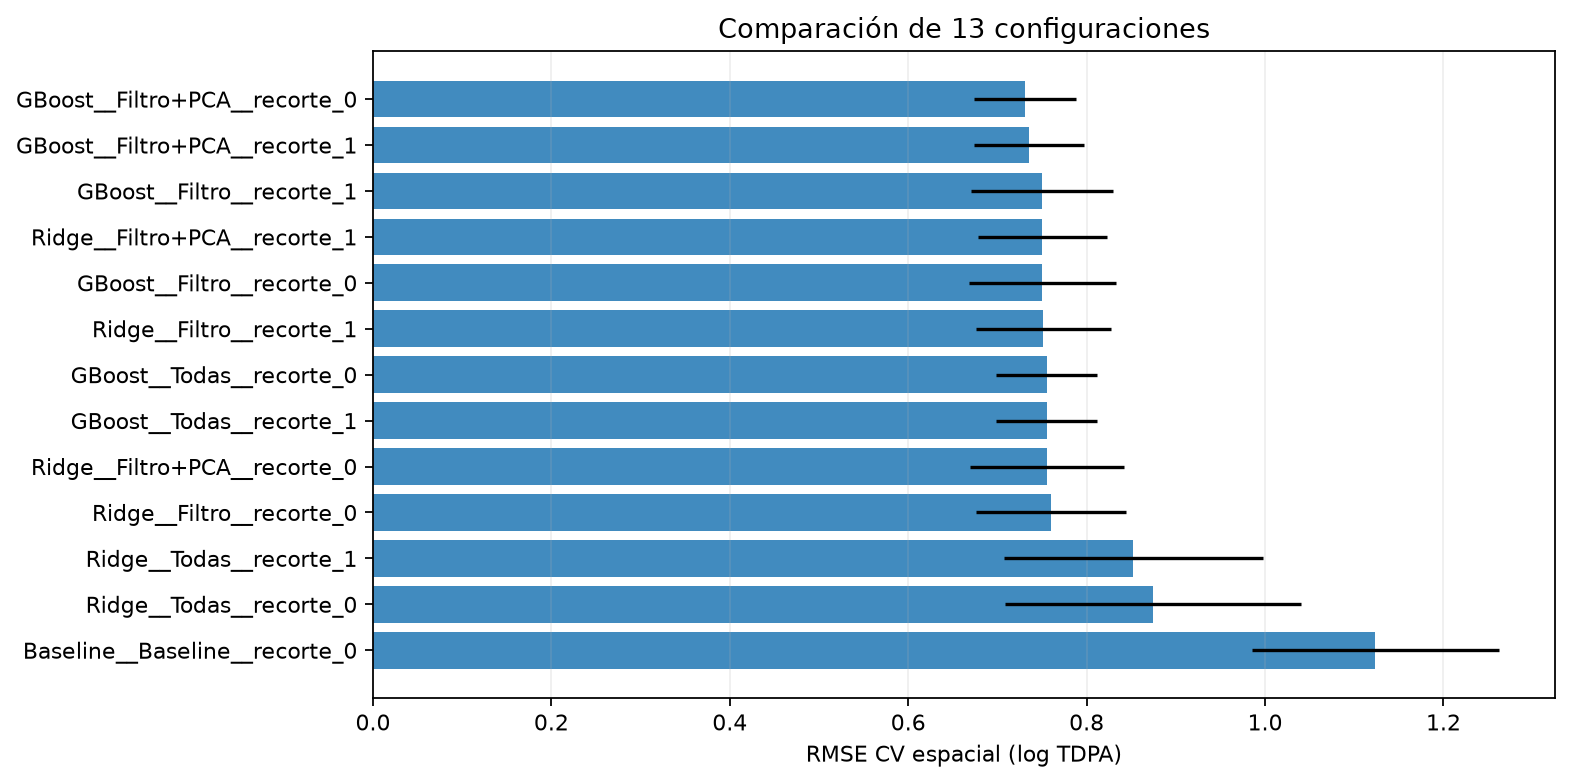

Baseline CV RMSE log: 1.1237
Umbral provisional: 0.8428
Candidato elegido: GBoost__Filtro+PCA__recorte_0
Reducción RMSE vs baseline: 34.93 %


In [10]:
UMBRAL_MEJORA_PCT = 25.0
rmse_base = float(res.loc[res.conjunto.eq("Baseline"), "rmse_cv_log"].iloc[0])
umbral_rmse = rmse_base * (1 - UMBRAL_MEJORA_PCT / 100)
res["mejora_vs_baseline_pct"] = 100 * (1 - res["rmse_cv_log"] / rmse_base)
res["cumple_umbral_provisional"] = res["rmse_cv_log"] <= umbral_rmse
res.sort_values("rmse_cv_log").to_csv(OUT_DIR / "comparacion_modelos.csv", index=False, encoding="utf-8-sig")
grafica_comparacion(res, OUT_DIR / "comparacion_rmse.png")

display(res.sort_values("rmse_cv_log")[[
    "run_name", "rmse_cv_log", "rmse_cv_sd", "valid_mae_veh_dia",
    "train_rmse_log", "gap_rmse_log", "mejora_vs_baseline_pct", "cumple_umbral_provisional"
]].round(3))
display(Image(filename=str(OUT_DIR / "comparacion_rmse.png")))

candidatos = res.loc[res.conjunto.ne("Baseline")].sort_values(["rmse_cv_log", "n_features"])
ganador = candidatos.iloc[0]
config_ganadora = (str(ganador.conjunto), bool(ganador.recorte), str(ganador.algoritmo))
nombre_ganador = str(ganador.run_name)
print("Baseline CV RMSE log:", round(rmse_base, 4))
print("Umbral provisional:", round(umbral_rmse, 4))
print("Candidato elegido:", nombre_ganador)
print("Reducción RMSE vs baseline:", round(float(ganador.mejora_vs_baseline_pct), 2), "%")

**Interpretación de la gráfica comparativa.** Una barra más corta representa menor RMSE log de validación. GBoost con filtro y PCA **sin recorte** encabeza el orden (**0.7312**), seguido de la misma combinación con recorte (**0.7351**). El baseline es la alternativa de mayor error (**1.1237**). Los segmentos negros indican dispersión entre folds, **no** un intervalo de confianza: su superposición advierte que las diferencias pequeñas entre modelos próximos al primer lugar no son concluyentes por sí solas. Diez de las doce configuraciones de ML superan el umbral técnico provisional del 25 %; las dos variantes Ridge con todas las características no lo alcanzan.

## 7. Diagnóstico de subajuste y sobreajuste 

Para el modelo seleccionado se contrastan, por fold, RMSE, MAE y R² de entrenamiento contra los de validación. Una brecha de error elevada y consistente indica **dificultades de generalización** compatibles con sobreajuste, aunque también puede reflejar cambios de distribución entre territorios. El diagnóstico se complementa con gráficos de residuos definidos como **valor observado menos valor predicho**.

En la representación de residuos, los puntos por encima de cero corresponden a **subestimaciones** y los situados por debajo, a **sobreestimaciones**. La escala de vehículos/día es especialmente pertinente para identificar fallas con consecuencias importantes en la estimación del tránsito.

mae_log        mae_veh_dia            r2_log        rmse_log  \
conjunto_eval   train  valid       train      valid  train  valid    train   
fold                                                                         
1               0.302  0.509    4015.994   9046.671  0.862  0.671    0.399   
2               0.238  0.563    2311.675  11381.434  0.841  0.580    0.332   
3               0.224  0.586    5825.972   8672.021  0.932  0.438    0.282   
4               0.261  0.629    5058.241  11950.148  0.918  0.491    0.319   
5               0.230  0.557    2710.166  10384.341  0.902  0.539    0.285   

                      
conjunto_eval  valid  
fold                  
1              0.639  
2              0.749  
3              0.719  
4              0.788  
5              0.761

RMSE entrenamiento promedio: 0.3234
RMSE validación promedio: 0.7312
Brecha (valid - train): +0.4079
Métricas OOF agrupadas (no idénticas al promedio simple de folds): {'rmse_log': 0.7328887350771911, 'mae_log': 0.5687848636647651, 'r2_log': 0.5519002294667642, 'mae_veh_dia': 10284.418426041293, 'rmse_veh_dia': 21027.5808094004, 'wape_pct': 52.875483477912134}


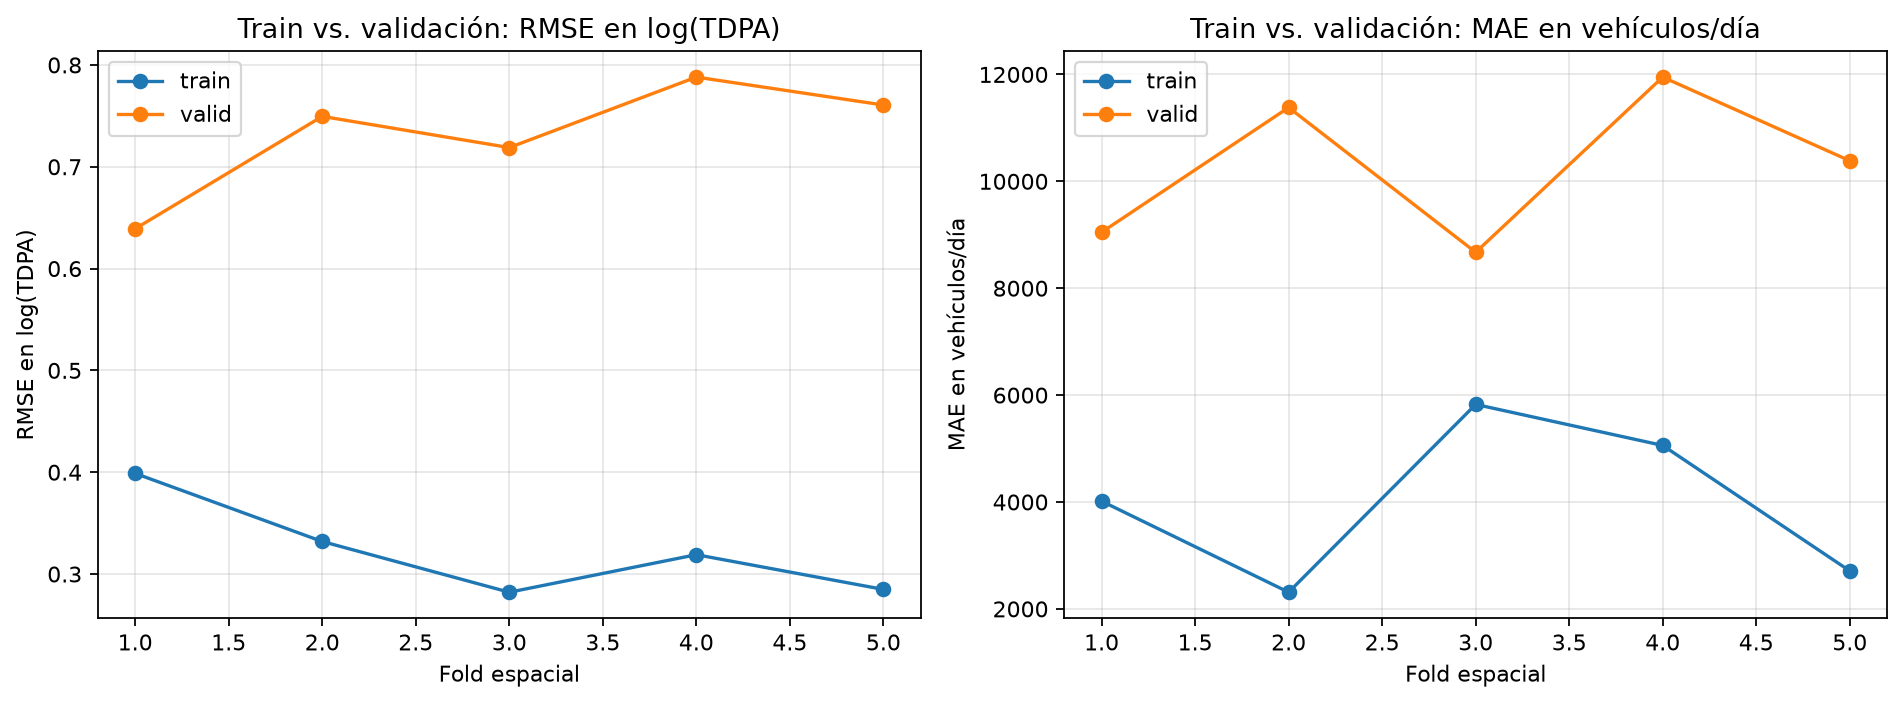

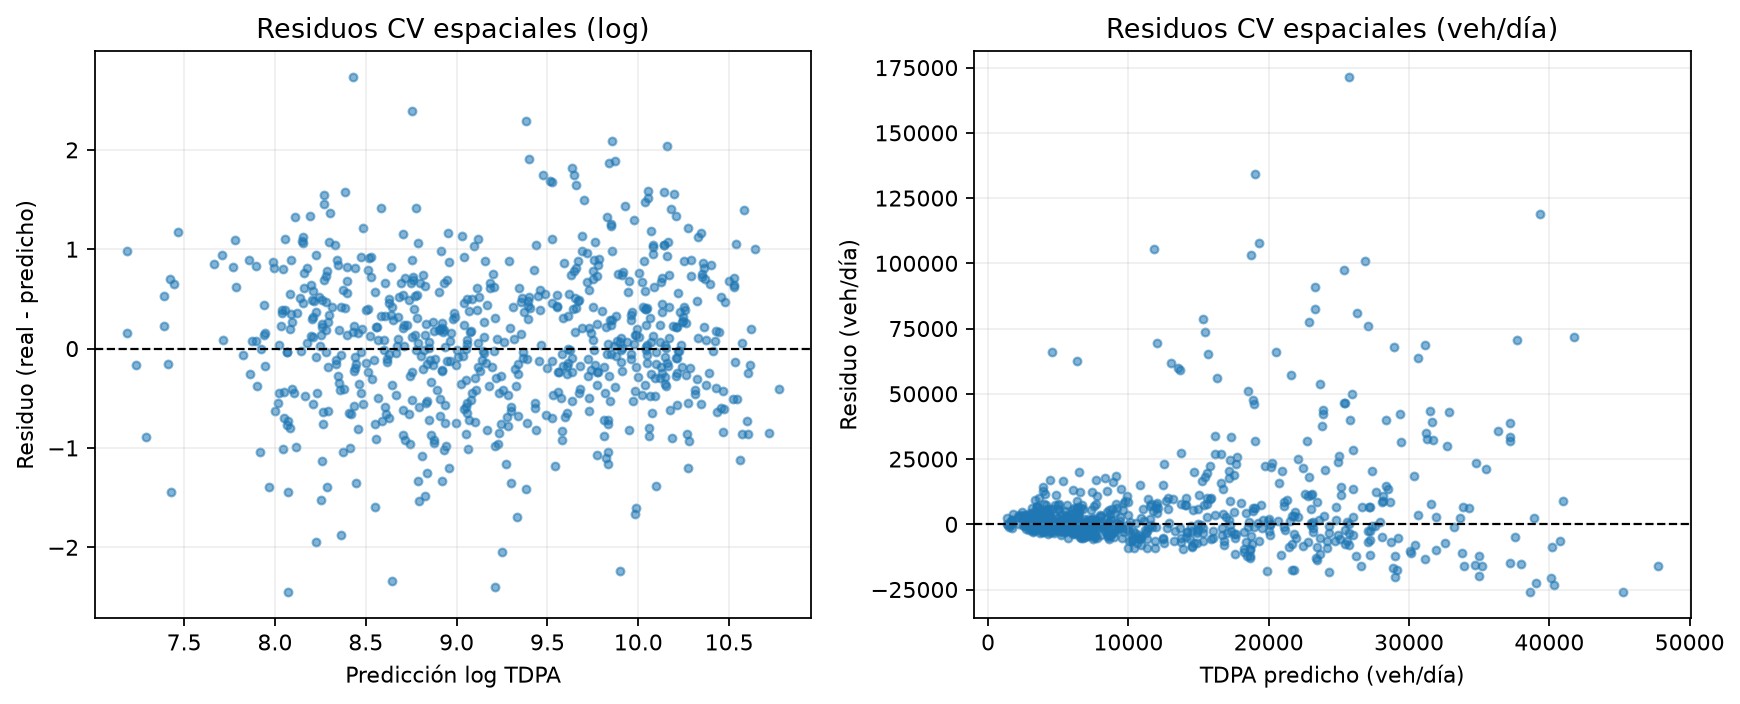

In [11]:
det_ganador = det.loc[det.run_name.eq(nombre_ganador)].copy()
ganador_oof = oof.loc[oof.run_name.eq(nombre_ganador)].copy()
grafica_cv(det_ganador, OUT_DIR / "ajuste_train_valid.png")
grafica_residuos(ganador_oof, OUT_DIR / "residuos_cv.png")

resumen_oof = calcular_metricas(
    ganador_oof.real_log, ganador_oof.pred_log,
    ganador_oof.real_veh_dia, ganador_oof.pred_veh_dia
)
display(det_ganador.pivot_table(
    index="fold", columns="conjunto_eval",
    values=["rmse_log", "mae_log", "r2_log", "mae_veh_dia"]
).round(3))
print(f"RMSE entrenamiento promedio: {ganador.train_rmse_log:.4f}")
print(f"RMSE validación promedio: {ganador.valid_rmse_log:.4f}")
print(f"Brecha (valid - train): {ganador.gap_rmse_log:+.4f}")
print("Métricas OOF agrupadas (no idénticas al promedio simple de folds):", resumen_oof)
display(Image(filename=str(OUT_DIR / "ajuste_train_valid.png")))
display(Image(filename=str(OUT_DIR / "residuos_cv.png")))

**Interpretación de las gráficas de ajuste y residuos.** En los cinco folds, la línea de validación queda por encima de la de entrenamiento tanto en RMSE log como en MAE absoluto. La brecha media del RMSE log (**0.4079**) señala dificultades de generalización compatibles con sobreajuste o diferencias entre regiones. Los residuos en log incluyen errores positivos y negativos de magnitud relevante; en vehículos/día, su dispersión se amplía al crecer el tránsito predicho y aparecen varios residuos positivos extremos, correspondientes a **subestimaciones**. Esta heterogeneidad es particularmente importante para el objetivo de planeación, porque los errores en sitios de mucho tráfico podrían tener impactos desproporcionados.

## 8. Relevancia e interpretación de las características 

El pipeline integra selección *filter* y, para la configuración correspondiente, PCA de predictores climáticos. Para evaluar qué variables de entrada contribuyen al desempeño del candidato se calcula **importancia por permutación sobre cada validación espacial**, expresada como el aumento del MAE log al alterar aleatoriamente una característica y mantener el modelo fijo.

Una importancia positiva indica que perturbar la variable empeora, en promedio, la predicción. Las barras de dispersión reflejan variabilidad entre permutaciones/folds; **no representan intervalos de confianza ni pruebas de causalidad**. Además, las variables correlacionadas pueden compartir importancia y las características no seleccionadas en un fold reciben contribución cero durante el promedio, lo que debe considerarse al interpretar magnitudes pequeñas.

In [12]:
def importancia_cv(train_fe, folds, config, repeticiones, salida):
    """Importancia original por característica en validación, nunca en corredor externo.

    Para cada fold, se perturban sólo variables realmente utilizadas por su pipeline.
    Las no seleccionadas en ese fold reciben contribución cero (modelo no depende de ellas).
    Características correlacionadas pueden compartir/separar importancia; NO causalidad.
    """
    modo, recortar, modelo = config
    rng = np.random.default_rng(SEED)
    mediciones = []
    candidatos_globales = set()
    modelos = []
    for k, a, b in folds:
        m = modelo_seguro(modo, recortar, modelo)
        m.fit(train_fe.loc[a], train_fe.loc[a, TARGET])
        prep = m.named_steps["prep"]
        usadas = set(prep.num_seleccionadas_ + prep.cat_seleccionadas_ + prep.pca_cols_)
        candidatos_globales.update(usadas)
        modelos.append((k, m, b, usadas))
    for k, m, b, usadas in modelos:
        Xv = train_fe.loc[b]
        real = train_fe.loc[b, TARGET].to_numpy(float)
        ref = mean_absolute_error(real, m.predict(Xv))
        for c in sorted(usadas):
            for rep in range(repeticiones):
                copia = Xv.copy()
                copia[c] = rng.permutation(copia[c].to_numpy())
                delta = mean_absolute_error(real, m.predict(copia)) - ref
                mediciones.append(dict(fold=k, variable=c, rep=rep, delta_mae_log=float(delta)))
    medidas = pd.DataFrame(mediciones)
    ruta_csv(medidas, salida/"permutation_por_fold.csv")
    # Incluye 0 para columnas que NO fueron usadas por cada fold.
    completo = pd.MultiIndex.from_product(
        [range(1, len(folds)+1), sorted(candidatos_globales), range(repeticiones)],
        names=["fold", "variable", "rep"]
    ).to_frame(index=False)
    completo = completo.merge(medidas, on=["fold", "variable", "rep"], how="left")
    completo["delta_mae_log"] = completo["delta_mae_log"].fillna(0.0)
    imp = completo.groupby("variable").agg(
        delta_mae_log=("delta_mae_log", "mean"),
        sd_delta_mae_log=("delta_mae_log", "std"),
        n_evaluaciones=("delta_mae_log", "size")
    ).reset_index().sort_values("delta_mae_log", ascending=False)
    ruta_csv(imp, salida/"importancia_variables.csv")
    grafica_importancia(imp, salida/"importancia_top20.png")
    return imp

,variable,delta_mae_log,sd_delta_mae_log,n_evaluaciones
37,road_circula,0.1673,0.0458,15
2,denue_n_gas_stations_5km,0.0497,0.0432,15
3,denue_n_large_est_5km,0.0374,0.0419,15
26,n_intersections_1km,0.0165,0.0141,15
35,road_ancho,0.0057,0.0064,15
40,rural_pop_share_10km,0.0052,0.0059,15
34,road_administra,0.0049,0.0122,15
1,denue_n_est_5km,0.0046,0.0098,15
49,t2m_mean,0.0044,0.0053,15
43,schooling_mean_10km,0.0043,0.0072,15


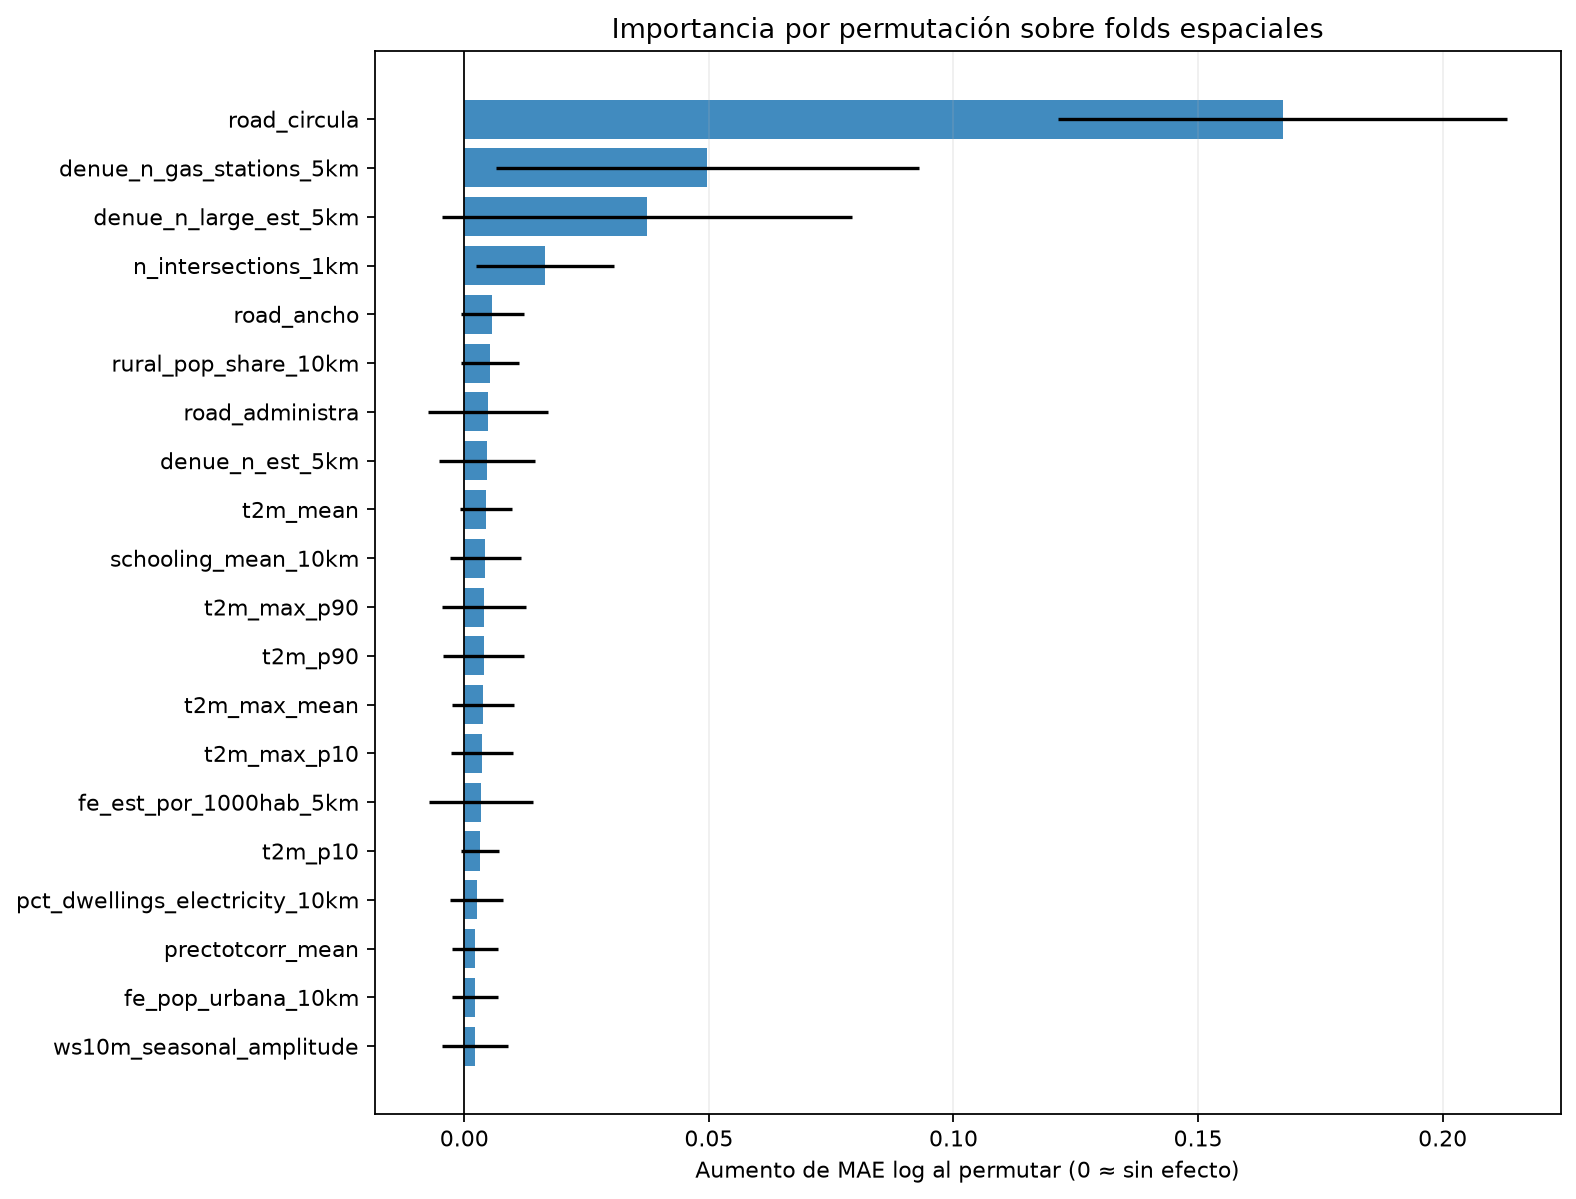

In [13]:
imp = importancia_cv(
    train_fe, folds, config_ganadora,
    repeticiones=REPETICIONES_IMPORTANCIA,
    salida=OUT_DIR
)
display(imp.head(20).round(4))
display(Image(filename=str(OUT_DIR / "importancia_top20.png")))

**Interpretación de la gráfica de importancia.** `road_circula` muestra el incremento medio más alto del MAE log al ser permutada (**0.1673**), muy por encima de `denue_n_gas_stations_5km` (**0.0497**) y `denue_n_large_est_5km` (**0.0374**). Las intersecciones a 1 km contribuyen en menor medida (**0.0165**). En numerosas variables posteriores, las barras de dispersión alcanzan o cruzan cero, por lo que su contribución individual debe considerarse **incierta en esta evaluación**, no necesariamente nula. La figura sugiere que la información vial es especialmente informativa, pero no prueba relaciones causales ni estabilidad universal de la jerarquía.

## 9. Evaluación del corredor externo reservado

Una vez identificado el mejor candidato sin consultar el conjunto externo, el pipeline se ajusta utilizando los **703 sitios de desarrollo** y se evalúa sobre los **23 sitios** del corredor reservado. Se registran métricas en escala log y en vehículos/día, junto con predicciones por sitio.

Esta evaluación corresponde a un corredor específico; por tanto, no debe extrapolarse su precisión a toda la red carretera. El modelo se serializa para reproducir estimaciones posteriores, sujeto a las mismas variables de entrada y versiones de bibliotecas. El archivo serializado solo debe cargarse desde fuentes confiables.

In [14]:
modelo_final = modelo_seguro(*config_ganadora)
modelo_final.fit(train_fe, train_fe[TARGET])
pred_test_log = np.asarray(modelo_final.predict(test_fe), dtype=float)
pred_test_tdpa = np.maximum(0, invertir_log(pred_test_log, transformacion))
metricas_externas = calcular_metricas(
    test_fe[TARGET], pred_test_log, test_fe.tdpa, pred_test_tdpa
)

tabla_externa = pd.DataFrame([{
    **metricas_externas, "conjunto": config_ganadora[0],
    "recorte": config_ganadora[1], "algoritmo": config_ganadora[2],
    "n_test": len(test_fe)
}])
predicciones_externas = pd.DataFrame({
    "site_id": test_fe.site_id.to_numpy(),
    "real_tdpa": test_fe.tdpa.to_numpy(), "pred_tdpa": pred_test_tdpa,
    "real_log_tdpa": test_fe[TARGET].to_numpy(),
    "pred_log_tdpa": pred_test_log,
    "residuo_tdpa": test_fe.tdpa.to_numpy() - pred_test_tdpa
})
tabla_externa.to_csv(OUT_DIR / "metricas_prueba_externa.csv", index=False, encoding="utf-8-sig")
predicciones_externas.to_csv(OUT_DIR / "predicciones_prueba_externa.csv", index=False, encoding="utf-8-sig")
features_guardar(modelo_final, OUT_DIR)

try:
    import cloudpickle
except ImportError as exc:
    raise ImportError("Para guardar el modelo instala cloudpickle en el kernel: %pip install cloudpickle") from exc
MODEL_PATH = MODELS_DIR / "tdpa_avance3_pipeline.pkl"
with MODEL_PATH.open("wb") as archivo:
    cloudpickle.dump(modelo_final, archivo)

display(tabla_externa.round(3))
display(predicciones_externas.head(10).round(2))
print("Pipeline guardado:", MODEL_PATH)

,rmse_log,mae_log,r2_log,mae_veh_dia,rmse_veh_dia,wape_pct,conjunto,recorte,algoritmo,n_test
0,0.663,0.495,0.285,16093.958,24807.405,44.715,Filtro + PCA,False,GBoost,23


,site_id,real_tdpa,pred_tdpa,real_log_tdpa,pred_log_tdpa,residuo_tdpa
0,S0068,69855.0,50838.28,11.15,10.84,19016.72
1,S0069,29636.0,27023.89,10.30,10.20,2612.11
2,S0070,44578.0,8566.35,10.70,9.06,36011.65
3,S0071,44510.0,12736.14,10.70,9.45,31773.86
4,S0072,42397.0,42751.86,10.65,10.66,-354.86
5,S0073,53630.0,47629.36,10.89,10.77,6000.64
6,S0197,91493.0,27782.53,11.42,10.23,63710.47
7,S0198,98629.5,35609.03,11.50,10.48,63020.47
8,S0199,70650.5,30989.45,11.17,10.34,39661.05
9,S0200,54976.0,22169.66,10.91,10.01,32806.34


Pipeline guardado: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\05_MODELS\tdpa_avance3_pipeline.pkl


**Interpretación de la evaluación externa.** En 23 sitios, el MAE es de **16,094 vehículos diarios**, el RMSE asciende a **24,807** y el **R² log es 0.285**, lo que refleja limitaciones importantes para representar diferencias de tránsito dentro de ese corredor. Aunque el RMSE log (**0.663**) es inferior al de validación (**0.7312**), ello no contrarresta los errores absolutos elevados. Los primeros registros muestran subestimaciones grandes, por ejemplo, en **S0197** y **S0198**. Se requiere mejorar el desempeño en ubicaciones de alto flujo antes de utilizar estas predicciones para asignar capacidad de recarga.

## 10. Trazabilidad de los resultados y control de versiones

El repositorio mantiene la separación existente entre `04_NOTEBOOKS` (análisis), `05_MODELS` (modelo serializado) y `06_RESULTS/AVANCE3` (tablas, gráficas y predicciones). La ejecución conserva configuraciones, métricas por fold, resultados externos, versión del entorno, hash SHA-256 de la tabla de características y commit de Git.

El hash verifica si se usó exactamente el mismo archivo, pero **no almacena ni permite recuperar** por sí solo los datos de ejecuciones anteriores. Asimismo, el commit registrado identifica la versión confirmada en GitHub; cambios locales sin confirmar no forman parte de ese commit. Esta trazabilidad facilitará una futura incorporación de MLflow, DagsHub o DVC.

In [15]:
def hash_sha256(path):
    sha = hashlib.sha256()
    with open(path, "rb") as archivo:
        for chunk in iter(lambda: archivo.read(1024 * 1024), b""):
            sha.update(chunk)
    return sha.hexdigest()

def git_estado(raiz):
    def cmd(*args):
        try:
            return subprocess.check_output(
                ["git", "-C", str(raiz), *args],
                text=True, stderr=subprocess.DEVNULL, timeout=10
            ).strip()
        except (OSError, subprocess.SubprocessError):
            return None
    sha = cmd("rev-parse", "HEAD")
    return {"git_commit": sha, "git_cambios_locales": bool(cmd("status", "--porcelain")) if sha else None}

metadatos = {
    "proyecto": "GreenStops",
    "avance": 3,
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_relativo": FE_PATH.relative_to(ROOT).as_posix(),
    "dataset_sha256": hash_sha256(FE_PATH),
    "notebook_sha256_guardado": hash_sha256(NOTEBOOK_FILE) if NOTEBOOK_FILE.is_file() else None,
    **git_estado(ROOT),
    "n_desarrollo": len(train_fe),
    "n_prueba_externa": len(test_fe),
    "n_folds": len(folds), "purga_km": BUFFER_KM,
    "variable_objetivo": TARGET,
    "transformacion_objetivo": transformacion,
    "umbral_mejora_pct": UMBRAL_MEJORA_PCT,
    "ganador_run_name": nombre_ganador,
    "semilla": SEED,
    "versiones": {"python": platform.python_version(), "numpy": np.__version__,
                  "pandas": pd.__version__, "scipy": scipy.__version__,
                  "sklearn": sklearn.__version__},
    "futuros_trackers": "Campos compatibles con futura instrumentación MLflow/DagsHub; no se conectan aquí"
}
(OUT_DIR / "manifiesto_versiones.json").write_text(
    json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Datos SHA-256:", metadatos["dataset_sha256"][:16] + "…")
print("Commit:", metadatos["git_commit"] or "No disponible")
print("Manifiesto:", OUT_DIR / "manifiesto_versiones.json")

Datos SHA-256: 6ffe2ae49ae99d5b…
Commit: 76d5f2adce4ff57eeea3312a31b29c7115440a92
Manifiesto: D:\TEC DE MONTERREY\maestria\Proyecto integrador\Equipo20_EnergyIntelligence\06_RESULTS\AVANCE3\manifiesto_versiones.json


**Trazabilidad de la ejecución.** El manifiesto registra la huella digital del CSV FE y el commit Git mostrado por el entorno. Esto permite identificar con mayor precisión qué entradas y qué versión confirmada del repositorio estuvieron asociadas con los resultados. El hash del notebook depende de que el archivo guardado coincida con la ruta indicada en la configuración; si se renombra, deberá adaptarse `NOTEBOOK_FILE`. No se publican credenciales ni se almacena aquí un seguimiento remoto.

## 11. Discusión y conclusiones del Avance 3

### 11.1. Calidad y alcance de los datos

La tabla procesada comprende **1,075 sitios y 274 columnas**. Se reservaron **23 sitios** del corredor de prueba, y la purga respecto de ese corredor excluyó **349 registros adicionales**, dejando **703 sitios de desarrollo**. La transformación de respuesta coincide con el logaritmo natural de TDPA. En los cinco folds, la purga espacial redujo los entrenamientos efectivos a **105–197 sitios**, frente a validaciones de **140–141 sitios**. Aunque este procedimiento refuerza la separación geográfica, el tamaño de entrenamiento por fold impone una limitación importante para modelos flexibles.

### 11.2. Selección de algoritmo y desempeño mínimo

Se compararon las **13 configuraciones** del Avance 2. El baseline obtuvo **RMSE log = 1.1237**, mientras que la configuración **GBoost + Filtro + PCA, sin recorte de valores extremos**, alcanzó **RMSE log = 0.7312** (desviación estándar entre folds: **0.057**). La reducción relativa es de **34.93 %**, superior al criterio técnico provisional del **25 %** (umbral RMSE log ≈ **0.8428**). La segunda configuración, GBoost con filtro y PCA y con recorte, obtuvo **0.7351**, por lo que el beneficio del recorte en este caso no se observa en el promedio de RMSE. Las barras de variación en la gráfica se superponen para varias configuraciones: las diferencias pequeñas **no demuestran por sí solas superioridad estadística**.

Se alcanza, por tanto, una mejora verificable **frente a la regla baseline en esta validación**, pero no puede afirmarse todavía que exista un nivel suficiente de precisión para decisiones de infraestructura. El umbral del 25 % es interno y fue definido con antecedentes de los experimentos, no con una tolerancia operativa independiente.

### 11.3. Sobreajuste y comportamiento de los residuos

Para el candidato seleccionado, el **RMSE log promedio de entrenamiento es 0.3234** y el de validación **0.7312**, con una **brecha de +0.4079**. El error de validación supera al de entrenamiento en los cinco folds, señal de **generalización limitada compatible con sobreajuste y/o cambios territoriales entre particiones**. La gráfica muestra además diferencias entre regiones: el RMSE de validación se sitúa aproximadamente entre **0.639 y 0.788**.

El gráfico de residuos en escala log presenta errores de ambos signos y casos extremos, mientras que en **vehículos/día** la dispersión crece claramente para predicciones de mayor tránsito. Se observan residuos positivos de gran magnitud, indicativos de **subestimaciones importantes** en algunos sitios. Esto advierte que el rendimiento medio no caracteriza adecuadamente todos los puntos, especialmente los de flujo elevado. Las predicciones agrupadas fuera de fold arrojan **MAE ≈ 10,284 vehículos/día**, **RMSE ≈ 21,028 vehículos/día**, **WAPE ≈ 52.88 %** y **R² log ≈ 0.552**. Estas métricas agrupadas no deben confundirse con el promedio simple de los cinco errores por fold.

### 11.4. Características relevantes e interpretación territorial

La importancia por permutación identifica a **`road_circula`** como la variable de mayor contribución, con incremento medio del MAE log de **0.1673** al desordenarla. Le siguen el número de estaciones de combustible en 5 km (**`denue_n_gas_stations_5km`**, **0.0497**), los establecimientos grandes próximos (**`denue_n_large_est_5km`**, **0.0374**) y las intersecciones a 1 km (**`n_intersections_1km`**, **0.0165**). Esta jerarquía sugiere que la caracterización vial y ciertos indicadores de actividad cercana son informativos para la estimación de tránsito.

La distancia entre la primera variable y el resto es evidente en la gráfica; sin embargo, las barras de dispersión de los siguientes predictores son relativamente amplias. Las importancias pequeñas de variables climáticas y demográficas **no demuestran irrelevancia**, dado que puede existir correlación entre atributos o selección distinta por fold. La interpretación es predictiva y no causal: la presencia de gasolineras, por ejemplo, no implica que estas generen por sí mismas mayor tránsito.

### 11.5. Evaluación sobre el corredor externo

El modelo ajustado sobre el conjunto de desarrollo obtuvo en los **23 sitios externos**: **RMSE log = 0.663**, **MAE log = 0.495**, **R² log = 0.285**, **MAE = 16,094 vehículos/día**, **RMSE = 24,807 vehículos/día** y **WAPE = 44.72 %**. Aunque el RMSE log externo es menor que el promedio de la validación espacial, el error absoluto diario sigue siendo considerable; ambas escalas responden a distintas distribuciones de tránsito y no deben utilizarse para declarar una mejora general de precisión.

La tabla de predicciones muestra ejemplos concretos de subestimación importante: el sitio **S0197** registró **91,493 vehículos/día** frente a unos **27,783 predichos**, y **S0198** registró **98,630** frente a unos **35,609 predichos**. Estos casos evidencian el riesgo de infraestimar puntos de alto flujo. La prueba externa es pequeña y territorialmente concentrada, por lo que sus resultados deben interpretarse como una primera evaluación de transferencia espacial y no como una garantía nacional.

### 11.6. Conclusión general y trabajo posterior

El avance demuestra que un modelo no lineal con selección de variables y PCA **supera sustancialmente el baseline** en la validación planteada y permite identificar factores viales y territoriales asociados con la predicción del TDPA. Sin embargo, la brecha entre entrenamiento y validación, la dispersión de residuos y los errores absolutos del corredor reservado indican que **la precisión actual aún necesita mejoras y una tolerancia de negocio explícita** antes de emplearse para dimensionar estaciones de carga.

Como continuidad metodológica se propone estudiar sesgo en sitios de alto tránsito, calibrar las estimaciones en escala original, comparar configuraciones más simples o con mayor regularización, ampliar la validación territorial y documentar la variación entre folds. Cuando se cuente con evidencia de precisión suficiente, el TDPA podrá usarse como una **variable de entrada** de un modelo independiente que incorpore adopción de vehículos eléctricos, probabilidad de recarga y consumo energético. El notebook conserva tablas, predicciones, parámetros y metadatos para facilitar la futura implementación de **MLflow + DagsHub** sin repetir innecesariamente la ingeniería de características.

> **Nota de reproducibilidad:** estas conclusiones fueron elaboradas a partir de las salidas conservadas en el archivo entregado. Si se actualizan datos, particiones, semillas o modelos, deberán revisarse los valores numéricos y las interpretaciones antes de publicar una nueva versión.